fps=30.00, frames=982, length=32.7s
Estimated HR: 58.7 BPM | True: 58 | Error: 0.7 BPM
Mean HR over time: 58.0 BPM (range 54-61)


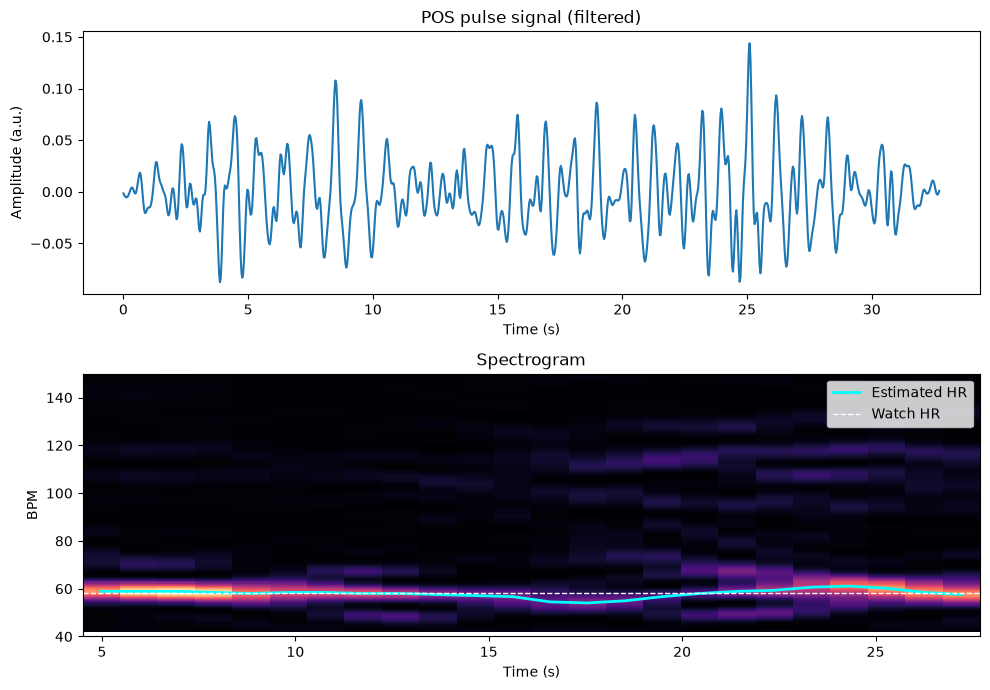

In [11]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, spectrogram

VIDEO = r"C:\Users\amitt\OneDrive\Desktop\Projects\IMG_6215.MOV"
TRUE_HR = 58

# ---------- 1. Open the video ----------
cap = cv2.VideoCapture(VIDEO)
if not cap.isOpened():
    raise SystemExit("Could not open video - check the path")
fps = cap.get(cv2.CAP_PROP_FPS)

# ---------- 2. Skin region (ROI) - forehead ----------
x1, x2, y1, y2 = 575, 775, 585, 685
ok, first = cap.read()

# ---------- 3. Average ROI color per frame ----------
rgb = []
while True:
    ok, frame = cap.read()
    if not ok:
        break
    roi = frame[y1:y2, x1:x2]
    rgb.append(roi.mean(axis=(0, 1))[::-1])     # BGR -> RGB
cap.release()
rgb = np.array(rgb)
N = len(rgb)
print(f"fps={fps:.2f}, frames={N}, length={N/fps:.1f}s")

# ---------- 4. POS algorithm ----------
l = int(1.6 * fps)
P = np.array([[0, 1, -1],
              [-2, 1, 1]])
H = np.zeros(N)
for t in range(N - l + 1):
    C = rgb[t:t + l]
    Cn = C / C.mean(axis=0)
    S = P @ Cn.T
    alpha = S[0].std() / (S[1].std() + 1e-9)
    h = S[0] + alpha * S[1]
    H[t:t + l] += h - h.mean()

# ---------- 5. Bandpass 0.7-4 Hz (42-240 BPM) ----------
b, a = butter(3, [0.7, 4.0], btype="band", fs=fps)
Hf = filtfilt(b, a, H)

# ---------- 6. FFT -> heart rate ----------
freqs = np.fft.rfftfreq(N, d=1 / fps)
mag = np.abs(np.fft.rfft(Hf))
band = (freqs >= 0.7) & (freqs <= 4.0)
bpm = freqs[band][np.argmax(mag[band])] * 60
print(f"Estimated HR: {bpm:.1f} BPM | True: {TRUE_HR} | Error: {abs(bpm - TRUE_HR):.1f} BPM")

# ---------- 7. Spectrogram: heart rate over time ----------
win = int(10 * fps)                          # 10 s windows: enough cycles for a clear peak
f, tt, Sxx = spectrogram(Hf, fs=fps,
                         nperseg=win,
                         noverlap=win - int(fps),   # slide 1 s each step
                         nfft=4096)                 # zero-padding = smoother frequency axis
band2 = (f >= 0.7) & (f <= 4.0)
f_bpm = f[band2] * 60
S = Sxx[band2]

hr_track = f_bpm[np.argmax(S, axis=0)]       # strongest frequency in each window
print(f"Mean HR over time: {hr_track.mean():.1f} BPM (range {hr_track.min():.0f}-{hr_track.max():.0f})")

t = np.arange(N) / fps
fig, ax = plt.subplots(2, 1, figsize=(10, 7))
ax[0].plot(t, Hf); ax[0].set_title("POS pulse signal (filtered)"); ax[0].set_xlabel("Time (s)")
ax[0].set_ylabel("Amplitude (a.u.)")
ax[1].pcolormesh(tt, f_bpm, S, shading="auto", cmap="magma")
ax[1].plot(tt, hr_track, c="cyan", lw=2, label="Estimated HR")
ax[1].axhline(TRUE_HR, c="white", ls="--", lw=1, label="Watch HR")
ax[1].set_ylim(40, 150)
ax[1].set_title("Spectrogram"); ax[1].set_xlabel("Time (s)"); ax[1].set_ylabel("BPM")
ax[1].legend(loc="upper right")
plt.tight_layout()
plt.savefig("rppg_spectrogram.png", dpi=150)
plt.show()

In [ ]:
import cupy as cp
x = cp.arange(10)
print(x * 2)
print(cp.cuda.runtime.getDeviceProperties(0)["name"])

In [7]:
!cp "/content/drive/MyDrive/IMG_6215.MOV" /content/video.mov

c:\Users\amitt\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\cupy\_environment.py:286: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


frames=983, grid=120x67, regions=8040
CPU: 18.94s | GPU: 0.66s | Speedup: 28.8x
Max BPM difference CPU vs GPU: 0.00
Strongest region HR: 45.8 BPM


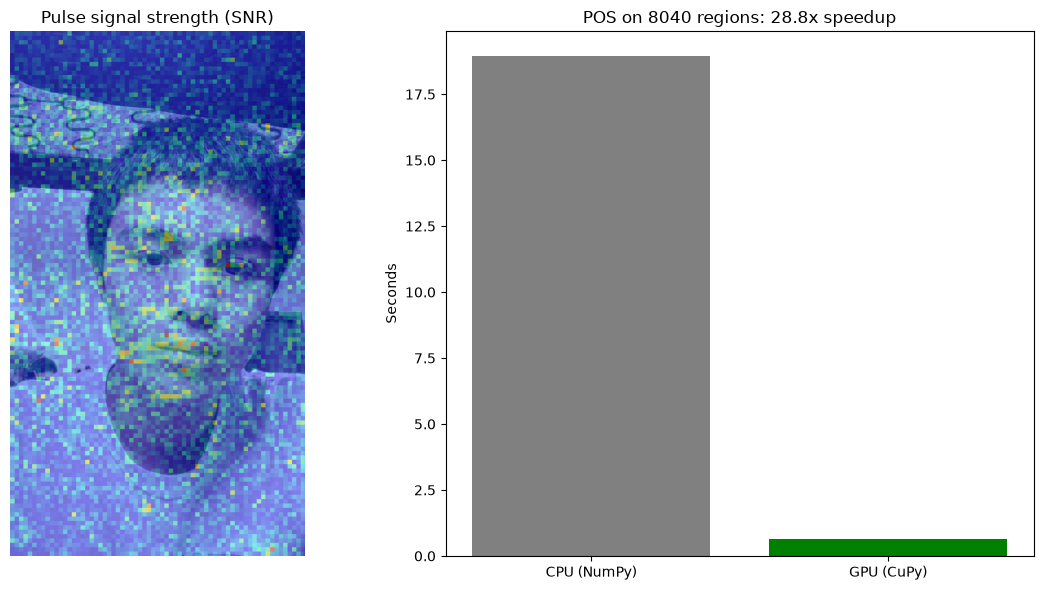

In [2]:
import time
import numpy as np
import cupy as cp
import cv2
import matplotlib.pyplot as plt

VIDEO = r"C:\Users\amitt\OneDrive\Desktop\Projects\IMG_6215.MOV"
SCALE = 16          # each block = average of a 16x16 pixel patch

# ---------- 1. Read video, shrink each frame into a grid of block averages ----------
cap = cv2.VideoCapture(VIDEO)
fps = cap.get(cv2.CAP_PROP_FPS)
frames, first = [], None
while True:
    ok, f = cap.read()
    if not ok:
        break
    if first is None:
        first = f
    small = cv2.resize(f, (f.shape[1] // SCALE, f.shape[0] // SCALE),
                       interpolation=cv2.INTER_AREA)       # INTER_AREA = block averaging
    frames.append(small[:, :, ::-1])                       # BGR -> RGB
cap.release()

V = np.asarray(frames, dtype=np.float32)                   # (N, h, w, 3)
N, h, w, _ = V.shape
X = V.reshape(N, h * w, 3).transpose(1, 0, 2).copy()       # (K regions, N frames, 3)
print(f"frames={N}, grid={h}x{w}, regions={h*w}")

# ---------- 2. POS for ALL regions at once ----------
# xp is either numpy or cupy -> the SAME code runs on CPU or GPU
def pos_all(X, fps, xp):
    K, N, _ = X.shape
    l = int(1.6 * fps)
    P = xp.asarray([[0, 1, -1], [-2, 1, 1]], dtype=xp.float32)
    H = xp.zeros((K, N), dtype=xp.float32)
    for t in range(N - l + 1):
        C = X[:, t:t + l, :]                                   # (K, l, 3)
        Cn = C / (C.mean(axis=1, keepdims=True) + 1e-6)        # normalize each region
        S = Cn @ P.T                                           # (K, l, 2)
        s1, s2 = S[..., 0], S[..., 1]
        alpha = s1.std(axis=1, keepdims=True) / (s2.std(axis=1, keepdims=True) + 1e-9)
        hh = s1 + alpha * s2
        H[:, t:t + l] += hh - hh.mean(axis=1, keepdims=True)
    # FFT per region -> heart rate + signal quality (SNR)
    spec = xp.abs(xp.fft.rfft(H, axis=1)) ** 2
    freqs = xp.fft.rfftfreq(N, d=1 / fps)
    band = (freqs >= 0.7) & (freqs <= 4.0)
    sb = spec[:, band]
    snr = sb.max(axis=1) / (sb.sum(axis=1) + 1e-12)            # how dominant the peak is
    bpm = freqs[band][sb.argmax(axis=1)] * 60
    return snr, bpm

# ---------- 3. Benchmark ----------
t0 = time.perf_counter()
snr_cpu, bpm_cpu = pos_all(X, fps, np)
cpu_s = time.perf_counter() - t0

pos_all(cp.asarray(X[:, :200]), fps, cp)                   # warm-up: first run compiles GPU kernels
cp.cuda.Stream.null.synchronize()

t0 = time.perf_counter()
Xg = cp.asarray(X)                                         # include CPU->GPU copy (fair comparison)
snr_gpu, bpm_gpu = pos_all(Xg, fps, cp)
cp.cuda.Stream.null.synchronize()                          # wait for GPU to actually finish
gpu_s = time.perf_counter() - t0

snr_gpu, bpm_gpu = cp.asnumpy(snr_gpu), cp.asnumpy(bpm_gpu)
print(f"CPU: {cpu_s:.2f}s | GPU: {gpu_s:.2f}s | Speedup: {cpu_s/gpu_s:.1f}x")
print(f"Max BPM difference CPU vs GPU: {np.abs(bpm_cpu - bpm_gpu).max():.2f}")

# ---------- 4. Pulse heatmap ----------
snr_map = snr_gpu.reshape(h, w)
best = np.unravel_index(snr_map.argmax(), snr_map.shape)
print(f"Strongest region HR: {bpm_gpu.reshape(h, w)[best]:.1f} BPM")

big = cv2.resize(snr_map, (first.shape[1], first.shape[0]), interpolation=cv2.INTER_NEAREST)
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(cv2.cvtColor(first, cv2.COLOR_BGR2RGB))
ax[0].imshow(big, cmap="jet", alpha=0.45); ax[0].set_title("Pulse signal strength (SNR)"); ax[0].axis("off")
ax[1].bar(["CPU (NumPy)", "GPU (CuPy)"], [cpu_s, gpu_s], color=["gray", "green"])
ax[1].set_ylabel("Seconds"); ax[1].set_title(f"POS on {h*w} regions: {cpu_s/gpu_s:.1f}x speedup")
plt.tight_layout(); plt.savefig("rppg_gpu.png", dpi=150); plt.show()

In [5]:
top = snr_gpu >= np.percentile(snr_gpu, 95)          # best 5% of regions (~400)
print(f"Consensus HR (top 5% regions): {np.median(bpm_gpu[top]):.1f} BPM")

Consensus HR (top 5% regions): 53.1 BPM


In [10]:
# Face box in full-resolution pixel coordinates
fx1, fx2, fy1, fy2 = 575, 775, 585, 685

# Grid size, recomputed from the frame (same math as cv2.resize in the GPU cell)
grid_h, grid_w = first.shape[0] // SCALE, first.shape[1] // SCALE
assert grid_h * grid_w == snr_gpu.size, "Re-run the GPU cell first"

# Map onto the block grid
mask = np.zeros((grid_h, grid_w), dtype=bool)
mask[fy1 // SCALE:fy2 // SCALE, fx1 // SCALE:fx2 // SCALE] = True
m = mask.ravel()

snr_f, bpm_f = snr_gpu[m], bpm_gpu[m]
top = snr_f >= np.percentile(snr_f, 75)
print(f"Face regions: {m.sum()} | Face consensus HR: {np.median(bpm_f[top]):.1f} BPM")

Face regions: 78 | Face consensus HR: 58.6 BPM
